Task 1: Install PyTorch

*PyTorch was loaded successfully in Google Colab. The code imports torch, torch.nn (for building neural networks), torch.optim (for optimizers), matplotlib (for visualization), and torchvision and DataLoader (for loading the dataset). The output shows PyTorch version 2.11.0 (CPU build), which confirms that the installation and import work correctly.*

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

print("PyTorch version:", torch.__version__)

PyTorch version: 2.11.0+cu130


Task 2: Download and Load the Dataset

The MNIST dataset was downloaded directly from the Python code using torchvision.datasets.MNIST and saved in the ./data folder. The progress bars confirm that the four dataset files were downloaded (100%). Each image was converted to a tensor with ToTensor() and normalized using the MNIST mean (0.1307) and standard deviation (0.3081). The training set contains 60,000 images and the test set contains 10,000 images. Two DataLoaders were created with a batch size of 32: the training loader shuffles the data, while the test loader does not. The message “Dataset loaded successfully” confirms the loading step finished without errors.

In [ ]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
])

train_set = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_set = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
test_loader = DataLoader(test_set, batch_size=32, shuffle=False)

print("Training images:", len(train_set))
print("Test images:", len(test_set))
print("Dataset loaded successfully")

100%|██████████| 9.91M/9.91M [00:00<00:00, 16.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 481kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.43MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.18MB/s]

Training images: 60000
Test images: 10000
Dataset loaded successfully


Task 3.1: Images tensor size

The first batch from the training loader has the shape torch.Size([32, 1, 28, 28]), which means: 32 images in the batch, 1 color channel (grayscale), and a height and width of 28×28 pixels. The labels tensor has the shape torch.Size([32]), which means one digit label (0–9) for each image in the batch.

In [ ]:
images, labels = next(iter(train_loader))
print("Images tensor size:", images.shape)
print("Labels tensor size:", labels.shape)

Images tensor size: torch.Size([32, 1, 28, 28])
Labels tensor size: torch.Size([32])


Task 3.2: Data visualization using matplotlib

The figure shows 16 sample images from the first training batch, displayed in grayscale with their true labels above each image (for example 1, 7, 5, 6, 3, 2, 9, 0). The images are 28×28 handwritten digits, white on a black background, and they differ in writing style and thickness. This confirms the data was loaded correctly and each image matches its label.

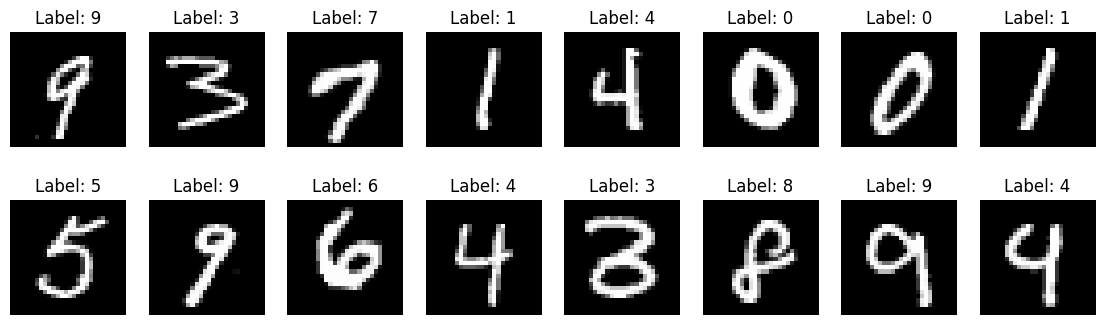

In [ ]:
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis("off")
plt.show()

*Task 4:A simple fully connected network was created with one hidden layer. The input (28×28 = 784 pixels) is connected to 128 hidden neurons through an nn.Linear layer, followed by a ReLU activation, and then a second nn.Linear layer connects the hidden neurons to the 10 output classes (digits 0–9). Since nn.Linear expects a 2D input (N × I), torch.flatten is used inside forward to rearrange the data. The printed shapes verify the requirement: the batch goes from (32 × 1 × 28 × 28) to (32 × 784), and the network outputs (32 × 10), one score per class for each image. The model has 101,770 trainable parameters.*

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class SimpleNet(nn.Module):

    def __init__(self, hidden_sizes=(128,)):
        super().__init__()
        layers = []
        in_features = 28 * 28  # 784
        for h in hidden_sizes:
            layers.append(nn.Linear(in_features, h))
            layers.append(nn.ReLU())
            in_features = h
        layers.append(nn.Linear(in_features, 10))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)  # (32,1,28,28) -> (32,784)
        return self.net(x)

net = SimpleNet([128]).to(device)
print(net)
print("Before flatten:", images.shape)
print("After flatten :", torch.flatten(images, start_dim=1).shape)
print("Output shape  :", net(images.to(device)).shape)
print("Total parameters:", sum(p.numel() for p in net.parameters()))

SimpleNet(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=10, bias=True)
  )
)
Before flatten: torch.Size([32, 1, 28, 28])
After flatten : torch.Size([32, 784])
Output shape  : torch.Size([32, 10])
Total parameters: 101770


Task 5 : The training function takes the network and the training dataloader, plus optional parameters (number of epochs, learning rate, momentum). It uses PyTorch’s nn.CrossEntropyLoss, which applies softmax to the network output and minimizes the negative log-likelihood of the correct class. The optimizer is stochastic gradient descent (optim.SGD) with a learning rate and momentum. For each mini-batch, the function clears the gradients, runs the forward pass, computes the loss, applies backpropagation (loss.backward()), and updates the weights (optimizer.step()). It prints the epoch, batch number, current loss, and accuracy, and returns the list of all mini-batch losses together with the average loss and accuracy of each epoch for plotting.

In [ ]:
def train(net, loader, epochs=3, lr=0.01, momentum=0.9, print_every=300, verbose=True):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(net.parameters(), lr=lr, momentum=momentum)

    batch_losses, epoch_losses, epoch_accs = [], [], []
    net.train()
    for epoch in range(1, epochs + 1):
        running_loss, correct, total = 0.0, 0, 0
        for batch_idx, (x, y) in enumerate(loader, start=1):
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            out = net(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()

            batch_losses.append(loss.item())
            running_loss += loss.item() * y.size(0)
            correct += (out.argmax(dim=1) == y).sum().item()
            total += y.size(0)

            if verbose and batch_idx % print_every == 0:
                print(f"Epoch {epoch}/{epochs} | Batch {batch_idx}/{len(loader)} | "
                      f"Loss: {loss.item():.4f} | Acc: {100 * correct / total:.2f}%")

        epoch_losses.append(running_loss / total)
        epoch_accs.append(100 * correct / total)
        if verbose:
            print(f"==> Epoch {epoch} done | Avg Loss: {epoch_losses[-1]:.4f} | "
                  f"Acc: {epoch_accs[-1]:.2f}%\n")
    return batch_losses, epoch_losses, epoch_accs

Task 6 : A new network (784 → 128 → 10) was instantiated and trained for 5 epochs using SGD with a learning rate of 0.01 and momentum of 0.9, with a batch size of 32 (1,875 mini-batches per epoch). The debug output prints the epoch, batch number, current mini-batch loss, and running accuracy every 300 batches, followed by a summary at the end of each epoch. The average loss decreased from 0.2223 in epoch 1 to 0.0373 in epoch 5, while the training accuracy increased from 93.36% to 98.77%. The improvement was largest in the first two epochs (accuracy 93.36% to 97.02%) and then became more gradual (97.96%, 98.46%, 98.77%), which means the network was converging. The graph of loss per mini-batch drops sharply at the start and then fluctuates at low values, because each mini-batch contains only 32 images and some batches are harder than others (for example, a loss of 0.2647 at epoch 2, batch 600). The graphs of loss per epoch and accuracy per epoch show a smooth decrease and increase, which confirms that the network is learning. Note that these are training results only; the network is evaluated on the test set in Task 7.

In [ ]:
net = SimpleNet([128]).to(device)
batch_losses, epoch_losses, epoch_accs = train(net, train_loader, epochs=5, lr=0.01, momentum=0.9)

Epoch 1/5 | Batch 300/1875 | Loss: 0.2544 | Acc: 84.88%
Epoch 1/5 | Batch 600/1875 | Loss: 0.1450 | Acc: 88.69%
Epoch 1/5 | Batch 900/1875 | Loss: 0.1551 | Acc: 90.50%
Epoch 1/5 | Batch 1200/1875 | Loss: 0.1663 | Acc: 91.76%
Epoch 1/5 | Batch 1500/1875 | Loss: 0.0415 | Acc: 92.51%
Epoch 1/5 | Batch 1800/1875 | Loss: 0.2358 | Acc: 93.09%
==> Epoch 1 done | Avg Loss: 0.2238 | Acc: 93.19%

Epoch 2/5 | Batch 300/1875 | Loss: 0.2597 | Acc: 97.02%
Epoch 2/5 | Batch 600/1875 | Loss: 0.0203 | Acc: 96.98%
Epoch 2/5 | Batch 900/1875 | Loss: 0.0903 | Acc: 97.06%
Epoch 2/5 | Batch 1200/1875 | Loss: 0.0335 | Acc: 97.05%
Epoch 2/5 | Batch 1500/1875 | Loss: 0.0503 | Acc: 97.14%
Epoch 2/5 | Batch 1800/1875 | Loss: 0.0806 | Acc: 97.14%
==> Epoch 2 done | Avg Loss: 0.0940 | Acc: 97.14%

Epoch 3/5 | Batch 300/1875 | Loss: 0.0135 | Acc: 98.02%
Epoch 3/5 | Batch 600/1875 | Loss: 0.0107 | Acc: 97.95%
Epoch 3/5 | Batch 900/1875 | Loss: 0.0096 | Acc: 97.90%
Epoch 3/5 | Batch 1200/1875 | Loss: 0.0644 | Acc: 97

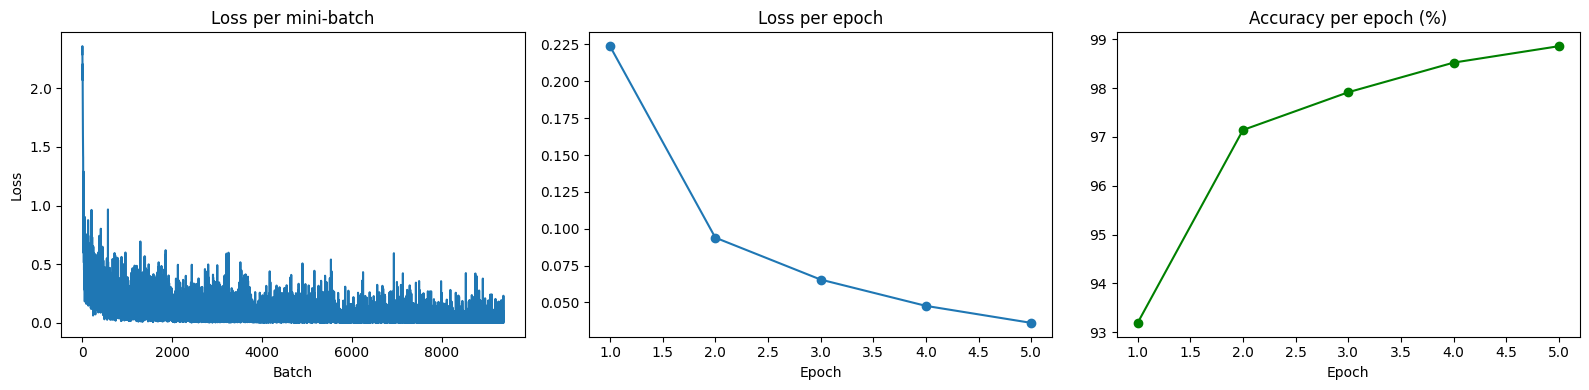

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(batch_losses)
axes[0].set_title("Loss per mini-batch")
axes[0].set_xlabel("Batch")
axes[0].set_ylabel("Loss")

axes[1].plot(range(1, len(epoch_losses) + 1), epoch_losses, marker="o")
axes[1].set_title("Loss per epoch")
axes[1].set_xlabel("Epoch")

axes[2].plot(range(1, len(epoch_accs) + 1), epoch_accs, marker="o", color="green")
axes[2].set_title("Accuracy per epoch (%)")
axes[2].set_xlabel("Epoch")
plt.tight_layout()
plt.show()

Task 7: Testing Network

The trained network from Task 6 is evaluated on the 10,000 test images that were never used during training. net.eval() switches the model to evaluation mode and torch.no_grad() turns off gradient tracking, because we only make predictions here (no weight updates).

In [ ]:
def evaluate(net, loader):
    criterion = nn.CrossEntropyLoss()
    net.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = net(x)
            total_loss += criterion(out, y).item() * y.size(0)
            correct += (out.argmax(dim=1) == y).sum().item()
            total += y.size(0)
    return total_loss / total, 100 * correct / total

test_loss, test_acc = evaluate(net, test_loader)
print(f"Test Loss    : {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.2f}%")
print(f"Train Accuracy (last epoch): {epoch_accs[-1]:.2f}%  vs  Test Accuracy: {test_acc:.2f}%")

Test Loss    : 0.0833
Test Accuracy: 97.55%
Train Accuracy (last epoch): 98.86%  vs  Test Accuracy: 97.55%


Task 7.1: Predictions on a few test images (green = correct, red = wrong)

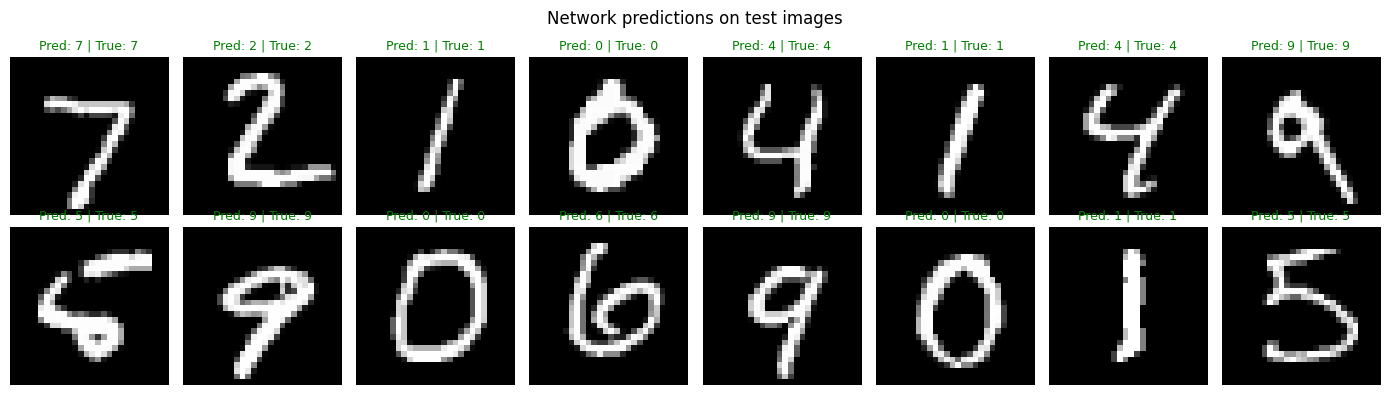

Correct predictions in this batch: 32 / 32


In [ ]:
test_images, test_labels = next(iter(test_loader))
net.eval()
with torch.no_grad():
    outputs = net(test_images.to(device))
    probs = torch.softmax(outputs, dim=1).cpu()
preds = probs.argmax(dim=1)

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(test_images[i].squeeze(), cmap="gray")
    color = "green" if preds[i] == test_labels[i] else "red"
    ax.set_title(f"Pred: {preds[i].item()} | True: {test_labels[i].item()}", color=color, fontsize=9)
    ax.axis("off")
plt.suptitle("Network predictions on test images")
plt.tight_layout()
plt.show()

print("Correct predictions in this batch:", (preds == test_labels).sum().item(), "/", len(test_labels))

Task 7.2: Class probabilities for one test image

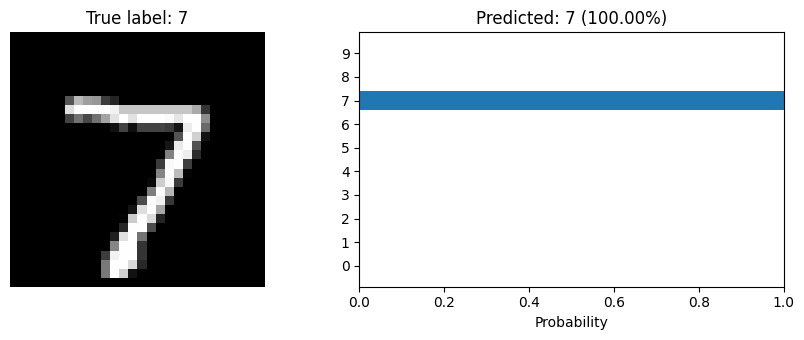

In [ ]:
idx = 0
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.5))
ax1.imshow(test_images[idx].squeeze(), cmap="gray")
ax1.set_title(f"True label: {test_labels[idx].item()}")
ax1.axis("off")
ax2.barh(range(10), probs[idx])
ax2.set_yticks(range(10))
ax2.set_xlim(0, 1)
ax2.set_xlabel("Probability")
ax2.set_title(f"Predicted: {preds[idx].item()} ({100 * probs[idx].max():.2f}%)")
plt.tight_layout()
plt.show()

Task 7.3: Accuracy for each digit on the full test set

Digit 0: 97.86%  (959/980)
Digit 1: 99.47%  (1129/1135)
Digit 2: 96.22%  (993/1032)
Digit 3: 98.91%  (999/1010)
Digit 4: 97.45%  (957/982)
Digit 5: 95.85%  (855/892)
Digit 6: 98.43%  (943/958)
Digit 7: 97.18%  (999/1028)
Digit 8: 95.79%  (933/974)
Digit 9: 97.92%  (988/1009)


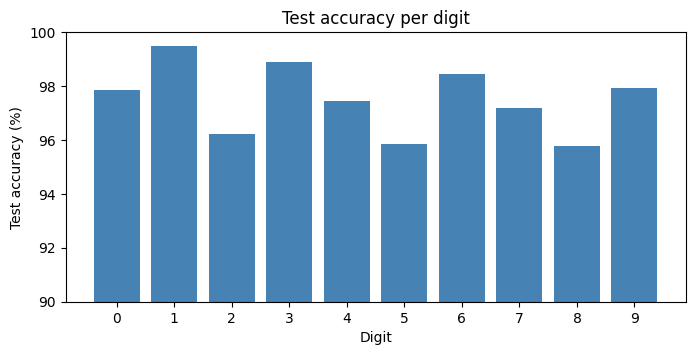

In [ ]:
class_correct = [0] * 10
class_total = [0] * 10
net.eval()
with torch.no_grad():
    for x, y in test_loader:
        p = net(x.to(device)).argmax(dim=1).cpu()
        for t, pr in zip(y, p):
            class_total[t.item()] += 1
            class_correct[t.item()] += int(t.item() == pr.item())

for d in range(10):
    print(f"Digit {d}: {100 * class_correct[d] / class_total[d]:.2f}%  ({class_correct[d]}/{class_total[d]})")

plt.figure(figsize=(8, 3.5))
plt.bar(range(10), [100 * c / t for c, t in zip(class_correct, class_total)], color="steelblue")
plt.xticks(range(10))
plt.ylim(90, 100)
plt.xlabel("Digit")
plt.ylabel("Test accuracy (%)")
plt.title("Test accuracy per digit")
plt.show()

Task 8: Tuning the parameters and model architecture
Every experiment uses the same random seed, so all models start from the same conditions and the comparison is fair. Each model is trained for 3 epochs and then judged on the test set (test loss and test accuracy).

In [ ]:
def run_experiment(hidden_sizes, lr, momentum, epochs=3, seed=0):
    torch.manual_seed(seed)
    model = SimpleNet(hidden_sizes).to(device)
    _, tr_losses, tr_accs = train(model, train_loader, epochs=epochs, lr=lr,
                                  momentum=momentum, verbose=False)
    te_loss, te_acc = evaluate(model, test_loader)
    return {"hidden": str(hidden_sizes), "lr": lr, "momentum": momentum,
            "train_loss": tr_losses[-1], "train_acc": tr_accs[-1],
            "test_loss": te_loss, "test_acc": te_acc}

EPOCHS = 3

Task 8.1: Tuning learning rate and momentum (architecture fixed: 784 → 128 → 10)

In [ ]:
import pandas as pd

learning_rates = [0.001, 0.01, 0.1]
momentums = [0.0, 0.5, 0.9]

results_lr = []
for lr in learning_rates:
    for m in momentums:
        r = run_experiment([128], lr, m, epochs=EPOCHS)
        results_lr.append(r)
        print(f"lr={lr:<6} momentum={m:<4} | Train Loss: {r['train_loss']:.4f} | "
              f"Test Loss: {r['test_loss']:.4f} | Test Acc: {r['test_acc']:.2f}%")

df_lr = pd.DataFrame(results_lr).sort_values("test_acc", ascending=False).reset_index(drop=True)
df_lr

lr=0.001  momentum=0.0  | Train Loss: 0.4157 | Test Loss: 0.3714 | Test Acc: 89.97%
lr=0.001  momentum=0.5  | Train Loss: 0.3334 | Test Loss: 0.3032 | Test Acc: 91.36%
lr=0.001  momentum=0.9  | Train Loss: 0.1920 | Test Loss: 0.1705 | Test Acc: 95.05%
lr=0.01   momentum=0.0  | Train Loss: 0.1913 | Test Loss: 0.1714 | Test Acc: 95.03%
lr=0.01   momentum=0.5  | Train Loss: 0.1308 | Test Loss: 0.1232 | Test Acc: 96.46%
lr=0.01   momentum=0.9  | Train Loss: 0.0645 | Test Loss: 0.0884 | Test Acc: 97.33%
lr=0.1    momentum=0.0  | Train Loss: 0.0631 | Test Loss: 0.0820 | Test Acc: 97.48%
lr=0.1    momentum=0.5  | Train Loss: 0.0725 | Test Loss: 0.1029 | Test Acc: 96.93%
lr=0.1    momentum=0.9  | Train Loss: 1.1996 | Test Loss: 1.7721 | Test Acc: 60.61%


,hidden,lr,momentum,train_loss,train_acc,test_loss,test_acc
0,[128],0.100,0.0,0.063124,98.053333,0.081986,97.48
1,[128],0.010,0.9,0.064512,97.980000,0.088440,97.33
2,[128],0.100,0.5,0.072501,97.721667,0.102939,96.93
3,[128],0.010,0.5,0.130818,96.261667,0.123207,96.46
4,[128],0.001,0.9,0.191973,94.545000,0.170524,95.05
5,[128],0.010,0.0,0.191305,94.626667,0.171435,95.03
6,[128],0.001,0.5,0.333379,90.580000,0.303178,91.36
7,[128],0.001,0.0,0.415665,88.883333,0.371441,89.97
8,[128],0.100,0.9,1.199629,64.991667,1.772105,60.61


Highest test accuracy: lr=0.1, momentum=0.0 -> 97.48% (loss 0.0820)
Lowest test loss     : lr=0.1, momentum=0.0 -> 0.0820 (acc 97.48%)


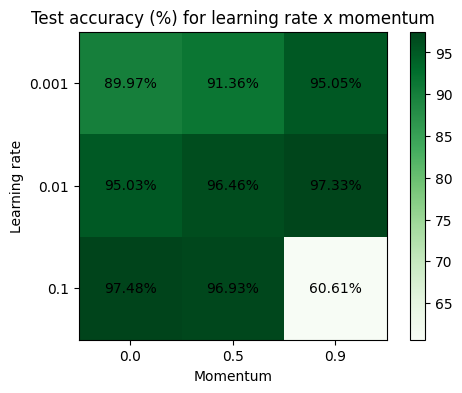

In [ ]:
best_acc_row = df_lr.loc[df_lr["test_acc"].idxmax()]
best_loss_row = df_lr.loc[df_lr["test_loss"].idxmin()]
print(f"Highest test accuracy: lr={best_acc_row['lr']}, momentum={best_acc_row['momentum']} "
      f"-> {best_acc_row['test_acc']:.2f}% (loss {best_acc_row['test_loss']:.4f})")
print(f"Lowest test loss     : lr={best_loss_row['lr']}, momentum={best_loss_row['momentum']} "
      f"-> {best_loss_row['test_loss']:.4f} (acc {best_loss_row['test_acc']:.2f}%)")

best_lr = float(best_acc_row["lr"])
best_momentum = float(best_acc_row["momentum"])

grid = df_lr.pivot(index="lr", columns="momentum", values="test_acc")
fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(grid.values, cmap="Greens")
ax.set_xticks(range(len(grid.columns)), grid.columns)
ax.set_yticks(range(len(grid.index)), grid.index)
ax.set_xlabel("Momentum")
ax.set_ylabel("Learning rate")
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        ax.text(j, i, f"{grid.values[i, j]:.2f}%", ha="center", va="center")
ax.set_title("Test accuracy (%) for learning rate x momentum")
plt.colorbar(im)
plt.show()

Task 8.2: Tuning the architecture (number of layers and neurons) with the best learning rate and momentum

In [ ]:
architectures = [
    [64], [128], [256], [512],          # 1 hidden layer
    [128, 64], [256, 128], [512, 256],  # 2 hidden layers
    [512, 256, 128],                    # 3 hidden layers
]

results_arch = []
for h in architectures:
    r = run_experiment(h, best_lr, best_momentum, epochs=EPOCHS)
    r["layers"] = len(h)
    r["params"] = sum(p.numel() for p in SimpleNet(h).parameters())
    results_arch.append(r)
    print(f"hidden={str(h):<16} layers={len(h)} params={r['params']:>7} | "
          f"Train Loss: {r['train_loss']:.4f} | Test Loss: {r['test_loss']:.4f} | "
          f"Test Acc: {r['test_acc']:.2f}%")

df_arch = pd.DataFrame(results_arch).sort_values("test_acc", ascending=False).reset_index(drop=True)
df_arch[["hidden", "layers", "params", "train_loss", "test_loss", "test_acc"]]

hidden=[64]             layers=1 params=  50890 | Train Loss: 0.0815 | Test Loss: 0.0867 | Test Acc: 97.47%
hidden=[128]            layers=1 params= 101770 | Train Loss: 0.0631 | Test Loss: 0.0820 | Test Acc: 97.48%
hidden=[256]            layers=1 params= 203530 | Train Loss: 0.0562 | Test Loss: 0.0849 | Test Acc: 97.32%
hidden=[512]            layers=1 params= 407050 | Train Loss: 0.0488 | Test Loss: 0.0690 | Test Acc: 97.74%
hidden=[128, 64]        layers=2 params= 109386 | Train Loss: 0.0680 | Test Loss: 0.0945 | Test Acc: 96.98%
hidden=[256, 128]       layers=2 params= 235146 | Train Loss: 0.0583 | Test Loss: 0.0959 | Test Acc: 96.91%
hidden=[512, 256]       layers=2 params= 535818 | Train Loss: 0.0508 | Test Loss: 0.0656 | Test Acc: 97.89%
hidden=[512, 256, 128]  layers=3 params= 567434 | Train Loss: 0.0565 | Test Loss: 0.0750 | Test Acc: 97.74%


,hidden,layers,params,train_loss,test_loss,test_acc
0,"[512, 256]",2,535818,0.050824,0.065626,97.89
1,[512],1,407050,0.048754,0.068980,97.74
2,"[512, 256, 128]",3,567434,0.056476,0.074956,97.74
3,[128],1,101770,0.063124,0.081986,97.48
4,[64],1,50890,0.081493,0.086730,97.47
5,[256],1,203530,0.056180,0.084932,97.32
6,"[128, 64]",2,109386,0.067993,0.094462,96.98
7,"[256, 128]",2,235146,0.058262,0.095917,96.91


Highest test accuracy: hidden=[512, 256] -> 97.89% (loss 0.0656)
Lowest test loss     : hidden=[512, 256] -> 0.0656 (acc 97.89%)


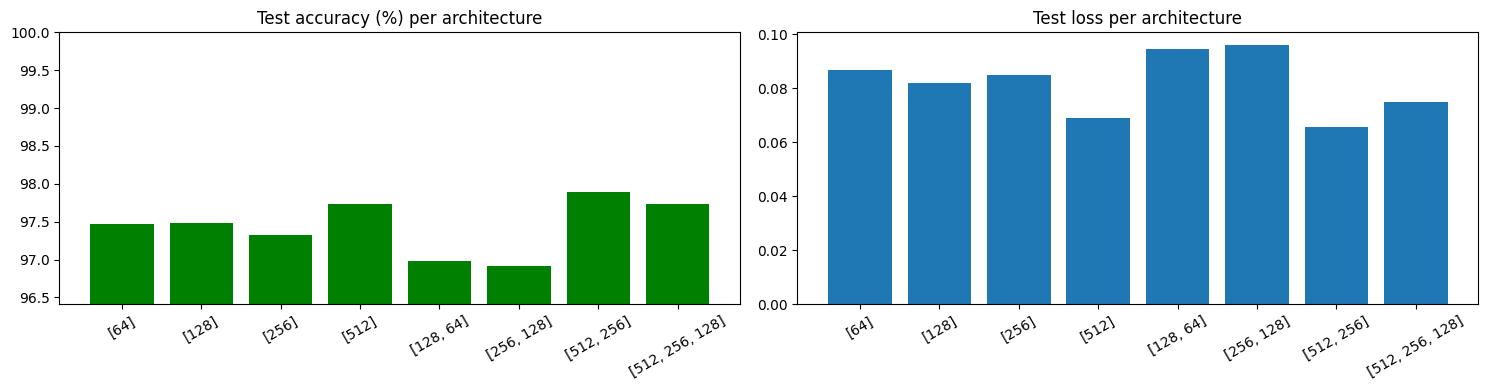

In [ ]:
best_arch_row = df_arch.loc[df_arch["test_acc"].idxmax()]
best_arch_loss_row = df_arch.loc[df_arch["test_loss"].idxmin()]
print(f"Highest test accuracy: hidden={best_arch_row['hidden']} -> {best_arch_row['test_acc']:.2f}% "
      f"(loss {best_arch_row['test_loss']:.4f})")
print(f"Lowest test loss     : hidden={best_arch_loss_row['hidden']} -> {best_arch_loss_row['test_loss']:.4f} "
      f"(acc {best_arch_loss_row['test_acc']:.2f}%)")

names = [r["hidden"] for r in results_arch]
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].bar(names, [r["test_acc"] for r in results_arch], color="green")
axes[0].set_ylim(min(r["test_acc"] for r in results_arch) - 0.5, 100)
axes[0].set_title("Test accuracy (%) per architecture")
axes[0].tick_params(axis="x", rotation=30)
axes[1].bar(names, [r["test_loss"] for r in results_arch])
axes[1].set_title("Test loss per architecture")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

Task 8.3: Final model with the best settings (trained 5 epochs, same as Task 6, for a fair comparison)

In [ ]:
best_hidden = eval(best_arch_row["hidden"])
torch.manual_seed(0)
best_net = SimpleNet(best_hidden).to(device)
print(best_net)
print(f"Best settings -> hidden layers: {best_hidden}, lr: {best_lr}, momentum: {best_momentum}\n")

b_batch_losses, b_epoch_losses, b_epoch_accs = train(best_net, train_loader, epochs=5,
                                                     lr=best_lr, momentum=best_momentum)
best_test_loss, best_test_acc = evaluate(best_net, test_loader)

print("=" * 60)
print(f"Baseline (Task 6, [128], lr=0.01, m=0.9): Test Loss {test_loss:.4f} | Test Acc {test_acc:.2f}%")
print(f"Best model ({best_hidden}, lr={best_lr}, m={best_momentum}): "
      f"Test Loss {best_test_loss:.4f} | Test Acc {best_test_acc:.2f}%")
print("=" * 60)

SimpleNet(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=10, bias=True)
  )
)
Best settings -> hidden layers: [512, 256], lr: 0.1, momentum: 0.0

Epoch 1/5 | Batch 300/1875 | Loss: 0.2804 | Acc: 83.90%
Epoch 1/5 | Batch 600/1875 | Loss: 0.0575 | Acc: 88.68%
Epoch 1/5 | Batch 900/1875 | Loss: 0.1904 | Acc: 90.52%
Epoch 1/5 | Batch 1200/1875 | Loss: 0.1217 | Acc: 91.80%
Epoch 1/5 | Batch 1500/1875 | Loss: 0.0075 | Acc: 92.56%
Epoch 1/5 | Batch 1800/1875 | Loss: 0.1713 | Acc: 93.21%
==> Epoch 1 done | Avg Loss: 0.2185 | Acc: 93.35%

Epoch 2/5 | Batch 300/1875 | Loss: 0.0041 | Acc: 97.97%
Epoch 2/5 | Batch 600/1875 | Loss: 0.1236 | Acc: 97.62%
Epoch 2/5 | Batch 900/1875 | Loss: 0.0816 | Acc: 97.57%
Epoch 2/5 | Batch 1200/1875 | Loss: 0.0086 | Acc: 97.53%
Epoch 2/5 | Batch 1500/1875 | Loss: 0.0368 | Acc: 97.53%
Epoch

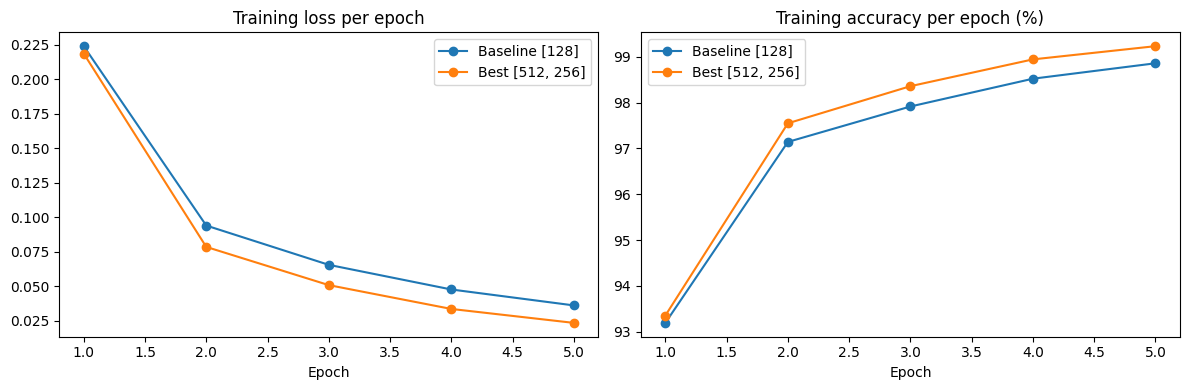

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, 6), epoch_losses, marker="o", label="Baseline [128]")
axes[0].plot(range(1, 6), b_epoch_losses, marker="o", label=f"Best {best_hidden}")
axes[0].set_title("Training loss per epoch")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[1].plot(range(1, 6), epoch_accs, marker="o", label="Baseline [128]")
axes[1].plot(range(1, 6), b_epoch_accs, marker="o", label=f"Best {best_hidden}")
axes[1].set_title("Training accuracy per epoch (%)")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()